In [1]:
from tqdm import tqdm # Optionnel ! Si vous ne l'avez pas sur votre distribution, vous pouvez tout simplement le retirer.
from time import perf_counter
from random import shuffle
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def tri_insertion(liste):
    for i in range(len(liste)):
        x = liste[i]
        j = i
        while j > 0 and liste[j - 1] > x:
            liste[j] = liste[j - 1]
            j = j - 1
        liste[j] = x
        
    return liste

In [3]:
def tri_selection(liste):
    for i in range(len(liste) - 1):
        minimum = i
        for j in range(i + 1, len(liste)):
            if liste[j] < liste[minimum]:
                minimum = j
        if minimum != i:
            liste[i], liste[minimum] = liste[minimum], liste[i]
    
    return liste

In [4]:
def tri_bulles(liste):
    for i in range(len(liste), 1, -1):
        for j in range(i - 1):
            if liste[j] > liste[j + 1]:
                liste[j], liste[j + 1] = liste[j + 1], liste[j]
                
    return liste

In [5]:
def afficher_liste(liste, nom_algorithme):
    print("Liste d'entrée, non-triée : " + str(liste))
    algorithmes = ["tri_insertion", "tri_selection", "tri_bulles"]
    assert (nom_algorithme in algorithmes), "Veuillez choisir un nom d'algorithme valide : " + str(algorithmes)
    
    for nom in algorithmes:
        if nom == nom_algorithme:
            liste_triee = eval(nom + "(liste)")
            print("Liste maintenant triée par " + nom_algorithme + " : " + str(liste_triee) + "\n")

In [6]:
liste = [2, 8, 4, 10, 6, 3, 3, 1]
noms_algorithmes = ["tri_insertion", "tri_selection", "tri_bulles"]

for nom in noms_algorithmes:
    tmp_liste = liste.copy()
    afficher_liste(tmp_liste, nom)

Liste d'entrée, non-triée : [2, 8, 4, 10, 6, 3, 3, 1]
Liste maintenant triée par tri_insertion : [1, 2, 3, 3, 4, 6, 8, 10]

Liste d'entrée, non-triée : [2, 8, 4, 10, 6, 3, 3, 1]
Liste maintenant triée par tri_selection : [1, 2, 3, 3, 4, 6, 8, 10]

Liste d'entrée, non-triée : [2, 8, 4, 10, 6, 3, 3, 1]
Liste maintenant triée par tri_bulles : [1, 2, 3, 3, 4, 6, 8, 10]



In [7]:
tailles_liste = [i for i in range(1, 2000)]

def mesure_temps(nom_algorithme, liste):
    debut = perf_counter()
    eval(nom_algorithme + "(liste)")
    duree_execution = perf_counter() - debut
    return duree_execution

In [8]:
temps_mesures = []

for taille in tqdm(tailles_liste): # Retirez le tqdm si vous ne l'avez pas installé.
    liste = [i for i in range(taille)]
    shuffle(liste)
    temps = []
    
    for nom in noms_algorithmes:
        tmp_liste = liste.copy()
        temps.append(mesure_temps(nom, tmp_liste))
        
    temps_mesures.append(temps)

100%|██████████████████████████████████████████████████████████████████████████████| 1999/1999 [08:05<00:00,  4.12it/s]


In [9]:
temps_mesures_tri_insertion = [liste_temps[0] for liste_temps in temps_mesures]
temps_mesures_tri_selection = [liste_temps[1] for liste_temps in temps_mesures]
temps_mesures_tri_bulles = [liste_temps[2] for liste_temps in temps_mesures]

In [10]:
complexite_asymptotique_tri_insertion = [2e-7 * taille ** 2 for taille in tailles_liste]

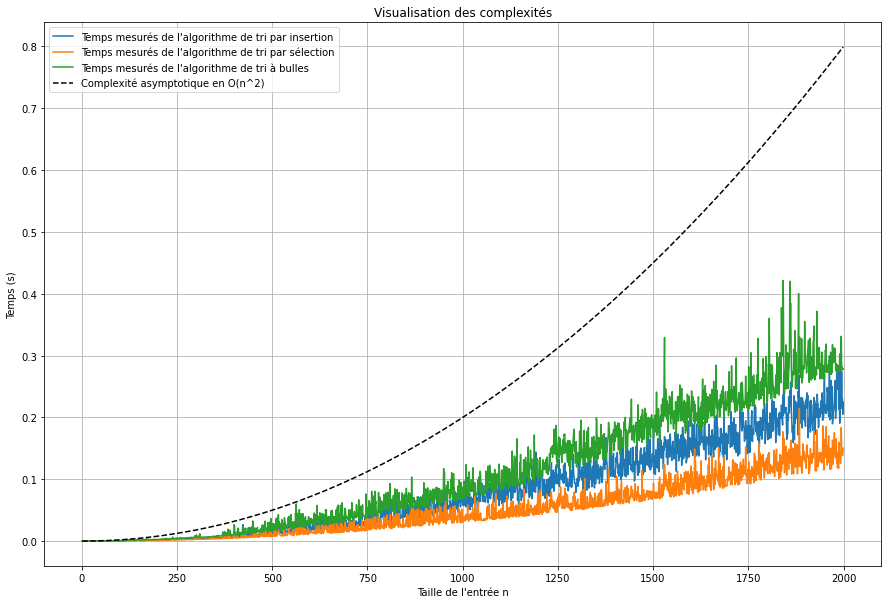

In [11]:
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(tailles_liste, temps_mesures_tri_insertion, label="Temps mesurés de l'algorithme de tri par insertion")
ax.plot(tailles_liste, temps_mesures_tri_selection, label="Temps mesurés de l'algorithme de tri par sélection")
ax.plot(tailles_liste, temps_mesures_tri_bulles, label="Temps mesurés de l'algorithme de tri à bulles")
ax.plot(tailles_liste, complexite_asymptotique_tri_insertion, label="Complexité asymptotique en O(n^2)", color='black', linestyle='dashed')

ax.set(xlabel="Taille de l'entrée n", ylabel="Temps (s)", title="Visualisation des complexités")
ax.grid()
plt.legend()

plt.show()

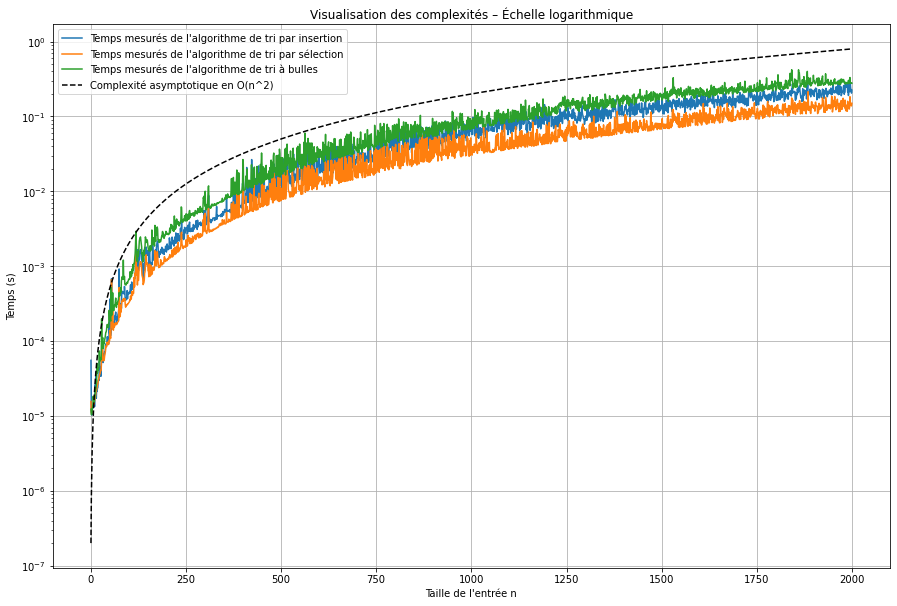

In [12]:
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(tailles_liste, temps_mesures_tri_insertion, label="Temps mesurés de l'algorithme de tri par insertion")
ax.plot(tailles_liste, temps_mesures_tri_selection, label="Temps mesurés de l'algorithme de tri par sélection")
ax.plot(tailles_liste, temps_mesures_tri_bulles, label="Temps mesurés de l'algorithme de tri à bulles")
ax.plot(tailles_liste, complexite_asymptotique_tri_insertion, label="Complexité asymptotique en O(n^2)", color='black', linestyle='dashed')

ax.set(xlabel="Taille de l'entrée n", ylabel="Temps (s)", title="Visualisation des complexités – Échelle logarithmique")
ax.grid()
ax.set_yscale('log')
plt.legend()

plt.show()

On observe bien que les trois algorithmes ont la même complexité asymptotique en $O(n^2)$. Il est intéressant de noter que tout de même, en réalité, il semble que certains algorithmes ont de meilleures performances que d'autres. Cela s'observe en particulier lorsque l'on regarde l'évolution du temps en fonction de la taille d'entée en échell logarithmique. En effet, bien que la notation asymptotique est une **famille** de fonctions, et que les trois notations asymptotiques sont les mêmes pour les trois algorithmes, les fonctions décrivant le nombre d'opérations à réaliser sont, elles, bien distinctes, et il serait tout à fait possible de les comparer. 

Ce qui au long cours va concrètement impacter la performance réelle de chacun de ces trois algorithmes est le facteur multiplicatif associé au terme quadratique de $f_p$ (ou $f_m$). Plus ce dernier sera grand, et plus le temps d'exécution sera long. 

D'après ces expérimentations, on observe que le meilleur algorithme semble être le tri par sélection, puis ensuite le tri par insertion et enfin le tri à bulles (car plus le temps est élevé, et moins l'algorithme est efficace dans sa consommation de ressources).

Il faut tout de même garder en tête que les courbes décrites ici sont issues de l'expérience, et qu'on observerait des résultats différents en fonction du ré-arrangement des listes pour les rendre « désordonnées », du système que vous utilisez, des fonctions de profiling que vous utilisez, etc.